d:\Work\GitHub\ML-For-Beginners\2-Regression\2-Data
                 Package     Date  Low Price  High Price
70  1 1/9 bushel cartons  9/24/16       15.0        15.0
71  1 1/9 bushel cartons  9/24/16       18.0        18.0
72  1 1/9 bushel cartons  10/1/16       18.0        18.0
73  1 1/9 bushel cartons  10/1/16       17.0        17.0
74  1 1/9 bushel cartons  10/8/16       15.0        15.0
      Month             Package  Low Price  High Price  Average Price  Price
1738      9  1/2 bushel cartons      15.00        15.0         15.000  30.00
1739      9  1/2 bushel cartons      13.75        15.0         14.375  28.75
1740      9  1/2 bushel cartons      10.75        15.0         12.875  25.75
1741      9  1/2 bushel cartons      12.00        12.0         12.000  24.00
1742      9  1/2 bushel cartons      12.00        12.0         12.000  24.00


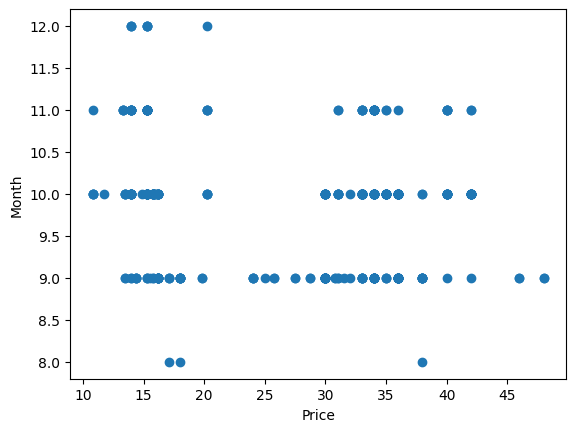

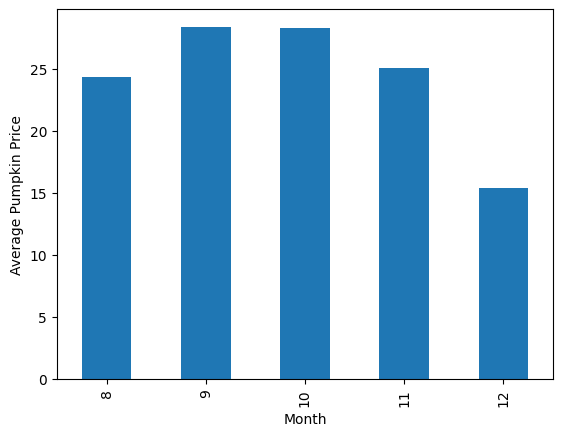

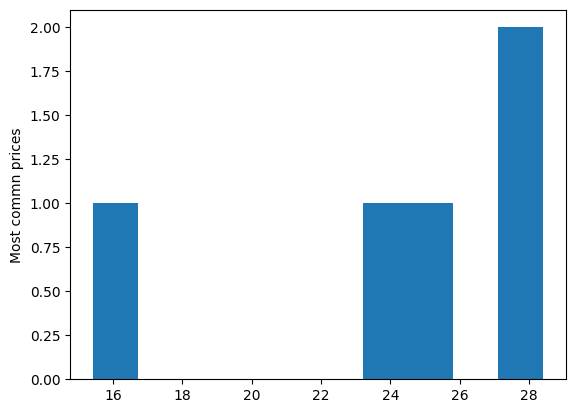

TypeError: Data source must be a DataFrame or Mapping, not <class 'pandas.core.series.Series'>.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sbr
import os

print(os.getcwd())
#read the US pumpkins CSV file
pumpkins = pd.read_csv('../data/US-pumpkins.csv')

#filter out any rows that don't use price per bushel
pumpkins = pumpkins[pumpkins['Package'].str.contains('bushel',case=True, regex=True)]

#print top 5 rows for verification
#pumpkins.head()

#count how many cells in each column are empty
pumpkins.isnull().sum()

#define the columns we want to keep
new_columns = ['Package', 'Month', 'Low Price', 'High Price', 'Date']
pumpkins = pumpkins.drop([c for c in pumpkins.columns if c not in new_columns], axis=1)
print(pumpkins.head())


#calculate the average proice between the high and low columns
price = (pumpkins['Low Price']+ pumpkins['High Price'])/2

#get the month from the date column
month = pd.DatetimeIndex(pumpkins['Date']).month

#create new dataframe with the two new columns
new_pumpkins = pd.DataFrame({'Month':month, 'Package' : pumpkins['Package'], 'Low Price':pumpkins['Low Price'], 'High Price':pumpkins['High Price'], 'Average Price':price})



#convert the price of all cells prices  in 1 1/9 bushels by dividing by 1 1/9
new_pumpkins.loc[new_pumpkins['Package'].str.contains('1 1/9'), 'Price'] = price/(1+1/9)

#convert the price of all cells prices  in 1/2 bushels by dividing by 1/2
new_pumpkins.loc[new_pumpkins['Package'].str.contains('1/2'), 'Price'] = price/(1/2)
print(new_pumpkins.tail())

price = new_pumpkins.Price
month = new_pumpkins.Month
plt.xlabel('Price')
plt.ylabel('Month')
plt.scatter(price, month)
plt.show()
#not very useful as all it does is display in my data as a spread of points in a given month.


#To get charts to display useful data, you usually need to group the data somehow. Let's try creating a plot where the y axis shows the months and the data demonstrates the distribution of data.
#Add a cell to create a grouped bar chart:

new_pumpkins.groupby(['Month'])['Price'].mean().plot(kind='bar')
plt.ylabel("Average Pumpkin Price")
plt.show()




#homework
new_pumpkins.groupby(['Month'])['Price'].mean().plot(kind='hist')
plt.ylabel("Most commn prices")
plt.show()

sbr.barplot(x='Month', y='Average Price', data =new_pumpkins)
plt.show()